# SPY implied-volatility smile around a Fed decision

Real September 17/19, 2024 quotes, common October 18 expiry. Event: September 18 FOMC rate cut. One descriptive before/after comparison, not causal inference.

## Setup

Install the repository first (`python -m pip install -e ".[notebook]"`). Select that environment as the notebook kernel. Run from the repository or its notebooks directory. Market notebooks require the documented data download first. Checked-in outputs are from an executed run; they are not fabricated data.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image

%matplotlib inline

## 1. Inspect data provenance

Run `python -m event_skew.data` first. The downloader queries public DoltHub option and underlying snapshots. No historical Yahoo chain is invented. Daily dates do not establish synchronized intraday quotes.

In [2]:
import json
from event_skew.model import compare
path=ROOT/'data/raw/options.csv'
assert path.exists(), 'Run python -m event_skew.data first'
data=pd.read_csv(path)
print('Real source quote count:',len(data))
manifest=json.loads((path.parent/'manifest.json').read_text())
print(manifest['provider']);print(manifest['event'])

Real source quote count: 76
DoltHub post-no-preference/options and stocks; third-party daily snapshots
FOMC September 18, 2024, 14:00 America/New_York


## 2. Quotes to implied volatility

Estimate forward carry from near-spot call-put parity. Invert the European Black model by root finding at bid, mid and ask. Use OTM puts below forward and calls above. Reject crossed/wide/noninvertible quotes. SPY options are American, so these are European-equivalent IVs, not exact American exercise-model estimates.

In [3]:
summary,quotes,curves,audit=compare(data,rate=.05)
display(pd.DataFrame(audit))
display(summary.round(6))

,raw_quotes,invalid_quotes,date,expiry,spot,forward,forward_pair_count,forward_pair_range,days_to_expiry,removed_itm_or_spread,inversion_failures,valid_otm_quotes,fit_quotes
0,38,0,2024-09-17,2024-10-18,563.07,563.954043,5,1.345542,31,23,0,15,10
1,38,0,2024-09-19,2024-10-18,570.98,571.365059,5,1.401900,29,22,0,16,9


,date,n,atm_iv,slope,curvature,rmse,domain_low,domain_high,atm_bid,slope_bid,curvature_bid,atm_ask,slope_ask,curvature_ask
0,2024-09-17,10,0.137683,-0.589635,11.248796,0.005809,-0.08463,0.073594,0.137541,-0.591834,11.101842,0.137829,-0.587577,11.389148
1,2024-09-19,9,0.126989,-0.514569,11.875550,0.003900,-0.08463,0.073594,0.126685,-0.515833,11.843119,0.127294,-0.513366,11.905702


## 3. Skew and curvature on comparable coordinates

Let $x=\log(K/F)$ and fit $IV(x)=a+bx+cx^2$ over the shared observed x-domain. ATM IV=a, local slope=b, curvature=2c. We never extrapolate beyond the shared domain. Same expiry is not same tenor: 31 days become 29. Bid/ask sensitivity is not a confidence interval.

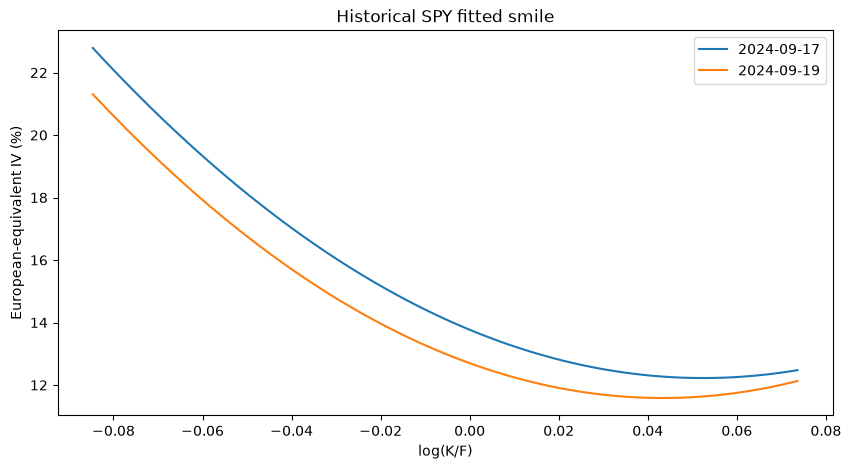

atm_iv      -0.010694
slope        0.075066
curvature    0.626754
Name: after_minus_before, dtype: object

In [4]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,5))
for date,d in curves.groupby('date'):
    ax.plot(d.log_moneyness,d.fitted_iv*100,label=date)
ax.set(xlabel='log(K/F)',ylabel='European-equivalent IV (%)',title='Historical SPY fitted smile');ax.legend();plt.show()
display((summary.iloc[1][['atm_iv','slope','curvature']]-summary.iloc[0][['atm_iv','slope','curvature']]).rename('after_minus_before'))

## 4. Stress the modelling assumption

The rate is assumed, not calibrated to an observed term structure. Repeat +/-100bp. Inspect parity dispersion, spread sensitivity, strike counts and fit residuals. Dividend/early-exercise effects, time decay and other news can explain changes. A quadratic fit can violate static arbitrage outside or even within its domain; it is not a pricing surface.

In [5]:
frames=[]
for rate in [.04,.05,.06]:
    s,_,_,_=compare(data,rate=rate);s['rate']=rate;frames.append(s)
display(pd.concat(frames)[['date','rate','atm_iv','slope','curvature']].round(6))

,date,rate,atm_iv,slope,curvature
0,2024-09-17,0.04,0.137612,-0.589379,11.260269
1,2024-09-19,0.04,0.126915,-0.513953,11.898190
0,2024-09-17,0.05,0.137683,-0.589635,11.248796
1,2024-09-19,0.05,0.126989,-0.514569,11.875550
0,2024-09-17,0.06,0.137754,-0.589890,11.237312
1,2024-09-19,0.06,0.127063,-0.515187,11.852894


## 5. Extend it

Try another common expiry and another event. Keep the selection rule explicit before seeing results. For future events, `python -m event_skew.data --snapshot-symbol SPY --expiry YYYY-MM-DD` saves current chains; the date is the expiration, not a historical observation date. Read [LEARNING.md](../LEARNING.md).